# EMQA_L7_foundation_hour

**Chronos-2 beats AW-LEAR in every hour of the day**

Energy Markets Quantitative Analysis (EMQA), Lecture 7 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L7/EMQA_L7_foundation_hour/EMQA_L7_foundation_hour.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Mean absolute error by hour of the day (CET) of the naive model, AW-LEAR and two pretrained time-series foundation models used zero-shot (Chronos-Bolt small and Chronos-2; context = the last 2048 hourly prices up to the end of d-1). Romanian day-ahead prices, test year 2025-11-01 to 2026-10-31. Data: test year 2025-11-01 to 2026-10-31; zero-shot, context = last 2048 hourly prices. Source: energy-charts.info (Fraunhofer ISE): OPCOM day-ahead prices for Romania.

The numbers printed at the end are those on the slide of Lecture 7.

## Setup: chart style and helpers

In [2]:
import io
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    "figure.facecolor": "none", "axes.facecolor": "none", "savefig.transparent": True,
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#222222", "axes.labelcolor": "#222222", "xtick.color": "#222222", "ytick.color": "#222222",
    "text.color": "#222222", "font.size": 11, "axes.titlesize": 11.5, "axes.labelsize": 11,
    "legend.fontsize": 10.5, "legend.frameon": False, "lines.linewidth": 1.4, "font.family": "DejaVu Sans"})
PAL = {"RO": "#2a78d6", "DE_LU": "#eb6834", "HU": "#1baf7a", "BG": "#eda100",
       "c5": "#e87ba4", "c6": "#008300", "c7": "#6250d6", "c8": "#e34948"}


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for hh, ll in zip(*ax.get_legend_handles_labels()):
                if ll not in labels:
                    handles.append(hh)
                    labels.append(ll)
    if handles:
        fig.legend(handles, labels, loc="lower center", ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
                   handlelength=2.0, columnspacing=1.2)


def save_chart(fig, name, bottom=0.17):
    fig.tight_layout(rect=(0, bottom, 1, 1))
    plt.savefig(name + ".png", dpi=150, bbox_inches="tight", transparent=True)
    plt.show()


def show(label, value, fmt=""):
    """Print a number that appears on the slide."""
    print(f"{label}: {format(value, fmt)}")

LAB = {"naive": "Naive", "aw_arx": "AW-ARX", "aw_lear": "AW-LEAR", "ens4": "Ens. of 4 (L2)", "gbm2": "GBM (L2)",
       "mlp2": "MLP (L2)", "xgb": "XGBoost", "dnn": "DNN", "bolt": "Chronos-Bolt", "chr2": "Chronos-2", "ens_ld": "LEAR+DNN",
       "ens_lx": "LEAR+XGBoost", "ens_ldx": "LEAR+DNN+XGBoost", "ens_t4": "Ens. of 4, tuned ML",
       "ens_t5": "Ens. of 5 (with Chronos-2)", "ens_lc": "LEAR+Chronos-2"}
COL = {"naive": "#9a9a9a", "aw_arx": PAL["HU"], "aw_lear": PAL["RO"], "ens4": PAL["c5"], "gbm2": "#c9a14a", "mlp2": "#a99be0",
       "xgb": PAL["BG"], "dnn": PAL["c7"], "bolt": "#6b6b6b", "chr2": PAL["c8"], "ens_ld": PAL["c6"], "ens_lx": PAL["c6"],
       "ens_ldx": PAL["DE_LU"], "ens_t4": PAL["DE_LU"], "ens_t5": PAL["DE_LU"], "ens_lc": "#7a1f1f"}

## Data: Romanian day-ahead prices, CET delivery day x 24 hours

In [3]:
TZ = "Europe/Brussels"


def day_matrix(s):
    """UTC-indexed hourly series -> CET delivery day x 24 hours (Assignment 1 / epftoolbox DST convention) + DST flag."""
    s = s.copy()
    s.index = pd.to_datetime(s.index, utc=True).tz_convert(TZ)
    df = pd.DataFrame({"v": s.values, "day": s.index.tz_localize(None).normalize(), "h": s.index.hour})
    m = df.groupby(["day", "h"])["v"].mean().unstack("h").reindex(columns=range(24))     # 25-h day: doubled hour averaged
    days = m.index
    nh = ((((days + pd.Timedelta(days=1)).tz_localize(TZ)) - days.tz_localize(TZ)) / pd.Timedelta(hours=1)).astype(int)
    dst = pd.Series(np.asarray(nh != 24), index=days)
    for dd in days[dst.values]:
        if pd.isna(m.loc[dd, 2]):
            m.loc[dd, 2] = 0.5 * (m.loc[dd, 1] + m.loc[dd, 3])                              # 23-h day: h02 = mean(h01, h03)
    m = m.dropna(how="any")
    return m, dst.reindex(m.index)


# Romanian day-ahead price (OPCOM PZU), hourly; after 1 Oct 2025 the hour is the mean of its four quarter-hours
HP = pd.read_csv(DATA + "power_da_prices_hourly_utc.csv", usecols=["timestamp_utc", "RO"], index_col=0)
PM_ALL, DST = day_matrix(HP["RO"].dropna())          # all CET delivery days since 2015 x 24 hours
# sample of the lecture: 2022-01-01 to the cut-off 2026-10-31 (last complete month at the download of 2026-11-04)
START, END = pd.Timestamp("2022-01-01"), pd.Timestamp("2026-10-31")
CAL = pd.date_range(START, END, freq="D")
PM = PM_ALL.reindex(CAL)
assert not PM.isna().any().any(), "panel has gaps"
P_ = PM.values.astype(float)
DOW = CAL.dayofweek.values
IDX = {t: i for i, t in enumerate(CAL)}
FIRST = 7                                             # first usable target row (needs the price of d-7)
TEST0 = END - pd.Timedelta(days=364)                  # test year = the last 365 days (as in Lecture 2)
VAL0 = TEST0 - pd.Timedelta(days=365)                 # validation year = the 365 days before it
TDAYS = pd.date_range(TEST0, END, freq="D")
VDAYS = pd.date_range(VAL0, TEST0 - pd.Timedelta(days=1), freq="D")
rows_all = np.array([IDX[t] for t in TDAYS])
A = P_[rows_all]                                      # actual prices of the test year (365 days x 24 hours), EUR/MWh
print("panel", CAL[0].date(), "to", CAL[-1].date(), "| test year", TEST0.date(), "to", END.date(), A.shape)

panel 2022-01-01 to 2026-10-31 | test year 2025-11-01 to 2026-10-31 (365, 24)


## Model outputs: saved, or recomputed with `RUN_ALL = True`

The models of this chart take several hours on one core (AW-LEAR; Chronos-2 and Chronos-Bolt run in about 10 minutes) to refit, more than a free Colab session allows. With `RUN_ALL = False` the notebook loads their saved outputs (`foundation_hour_results.npz`, produced by `lectures/L7/analysis_L7.py`); with `RUN_ALL = True` it recomputes them from the data with the code below, which is the code of the lecture.

In [4]:
RUN_ALL = False      # True: recompute the model outputs from the data (needs torch, xgboost, scikit-learn, chronos-forecasting)

Code of the models (copied from `lectures/L7/analysis_L7.py` and `lectures/L2/analysis_L2.py`); defining the functions takes no time.

In [5]:
import os
import time

# constants of lectures/L7/analysis_L7.py
SEED = 20261106
PLAGS, XLAGS = (1, 2, 3, 7), (2, 3, 7)            # price lags (days) and lags of load, wind+solar (>= 2 days)
XGB_NAMES = ['P(d-1,h)', 'P(d-2,h)', 'P(d-3,h)', 'P(d-7,h)', 'P(d-1,23)', 'min P(d-1)', 'max P(d-1)', 'mean P(d-1)', 'L(d-2,h)', 'L(d-7,h)', 'RES(d-2,h)', 'RES(d-7,h)', 'mean L(d-2)', 'mean RES(d-2)', 'hydro(d-2)', 'nuclear(d-2)', 'net imports(d-2)', 'EUA(d-2)', 'hour', 'day of week']
# configurations chosen by random search on the validation year (Quantlet EMQA_L7_search)
CFG_DNN = {'n1': 512, 'n2': 0, 'act': 'softplus', 'drop': 0.1, 'lr': 0.0003, 'wd': 1e-05, 'l1': 0.0, 'batch': 64, 'load': True, 'res': True, 'fund': True, 'p3': True}
CFG_XGB = {'n_est': 1500, 'eta': 0.02, 'depth': 8, 'mcw': 5, 'sub': 0.8, 'col': 1.0, 'lam': 0.1, 'obj': 'reg:absoluteerror'}
CTX = 2048                                     # context: the last 2048 hourly prices up to the end of d-1
SEED_L2 = 20261105                                # seed of Lecture 2
ARX_W, LEAR_W = (56, 84, 112, 714, 721, 728), (364, 546, 728)
GBM_NAMES = XGB_NAMES


def shift_rows(A, k):
    out = np.full_like(A, np.nan)
    out[k:] = A[:-k]
    return out


def mad_scale(x):
    x = np.asarray(x, float).ravel()
    m = np.median(x)
    s = stats.median_abs_deviation(x, scale="normal")
    return m, (s if s > 0 else 1.0)


def blocks_of(days, freq="M"):
    """(first row, last row) of each calendar month (or quarter) of a day range."""
    out = []
    for _, g in pd.Series(days, index=days).groupby(days.to_period(freq)):
        out.append((IDX[g.index[0]], IDX[g.index[-1]]))
    return out


def chronos_forecasts(Pa, rows, model):
    """Zero-shot: context = the last CTX hourly prices up to the end of d-1 (all known at gate closure), horizon 24 h."""
    import torch
    from chronos import BaseChronosPipeline
    torch.set_num_threads(1)                                    # one core, as for the other models (timing)
    pipe = BaseChronosPipeline.from_pretrained(model, device_map="cpu")
    t0 = time.perf_counter()
    ctx = np.stack([Pa[:i].ravel()[-CTX:] for i in rows]).astype("float32")
    x = torch.tensor(ctx)
    if "chronos-2" in model:
        x = x[:, None, :]
    q, _ = pipe.predict_quantiles(x, prediction_length=24, quantile_levels=[0.1, 0.5, 0.9])
    q = (torch.stack([x_.reshape(24, 3) for x_ in q]) if isinstance(q, list) else q).numpy().reshape(len(rows), 24, 3)
    return {"median": q[:, :, 1], "q": q, "sec": time.perf_counter() - t0}


# ---- benchmarks of Lecture 2 (lectures/L2/analysis_L2.py)
def lear_design(Pa, La, Ra, lo, i):
    """LEAR regressors (Assignment 1: 247 columns) for rows lo..i, with transforms fitted on rows available at gate closure."""
    m, s = mad_scale(Pa[lo - 7:i])
    mL, sL = mad_scale(La[lo - 7:i - 1])
    mR, sR = mad_scale(Ra[lo - 7:i - 1])
    rows = slice(lo, i + 1)
    blocks = [np.arcsinh((shift_rows(Pa, k)[rows] - m) / s) for k in PLAGS]
    blocks += [np.arcsinh((shift_rows(La, k)[rows] - mL) / sL) for k in XLAGS]
    blocks += [np.arcsinh((shift_rows(Ra, k)[rows] - mR) / sR) for k in XLAGS]
    blocks.append(np.eye(7)[DOW[rows]])
    X = np.column_stack(blocks)
    Y = np.arcsinh((Pa[rows] - m) / s)
    return X, Y, m, s


def lear_day(Pa, La, Ra, i, T):
    from sklearn.linear_model import LassoLarsIC
    lo = i - T
    X, Y, m, s = lear_design(Pa, La, Ra, lo, i)
    mu, sd = X[:-1].mean(0), X[:-1].std(0)
    sd[sd == 0] = 1.0
    Xs = (X - mu) / sd
    out, nz = np.zeros(24), np.zeros((24, X.shape[1]), bool)
    for h in range(24):
        mdl = LassoLarsIC(criterion="aic", max_iter=2000).fit(Xs[:-1], Y[:-1, h])
        out[h] = mdl.predict(Xs[-1:])[0]
        nz[h] = mdl.coef_ != 0
    return m + s * np.sinh(out), nz


QL = "EMQA_L7_foundation_hour"


def load_results(fname):
    """Saved outputs of the full computation, stored in this Quantlet folder (local copy, else the public repository)."""
    if os.path.isfile(fname):
        return dict(np.load(fname, allow_pickle=False))
    raw = urllib.request.urlopen(REPO + "Quantlets/L7/" + QL + "/" + fname).read()
    return dict(np.load(io.BytesIO(raw), allow_pickle=False))

In [6]:
if RUN_ALL:
    # ---- full information set at gate closure (12:00 CET on d-1), as in lectures/L7/analysis_L7.py
    from joblib import Parallel, delayed
    GH = pd.read_csv(DATA + "generation_ro_mw_hourly_utc.csv", index_col=0)
    LM, _ = day_matrix(GH["load"].dropna())
    RM, _ = day_matrix((GH["wind_onshore"] + GH["solar"]).dropna())
    L_, R_ = LM.reindex(CAL).values.astype(float), RM.reindex(CAL).values.astype(float)
    G = pd.read_csv(DATA + "generation_ro_mw_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
    CB = pd.read_csv(DATA + "crossborder_ro_mw_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
    EUA = pd.read_csv(DATA + "eua_daily.csv", parse_dates=["date"]).set_index("date")["eua_etc_co2l_eur_per_unit"]
    CAL_EX = pd.date_range(START - pd.Timedelta(days=30), END, freq="D")
    FUND_RAW = pd.DataFrame({"hydro": (G["hydro_run_of_river"] + G["hydro_water_reservoir"]).reindex(CAL_EX),
                             "nuclear": G["nuclear"].reindex(CAL_EX), "netimp": CB["sum"].reindex(CAL_EX), "eua": EUA.reindex(CAL_EX)})
    F_ = FUND_RAW.ffill().shift(2).reindex(CAL).values.astype(float)      # past only, lagged 2 days
    MB = blocks_of(TDAYS, "M")                                           # 12 monthly refits in the test year
    _vm = blocks_of(VDAYS, "M")
    VB = [(_vm[k][0], _vm[k + 2][1]) for k in range(0, 12, 3)]           # validation year: 4 quarterly refits
    FC = {}
    FC["naive"] = np.array([P_[i - 7] if DOW[i] in (0, 5, 6) else P_[i - 1] for i in rows_all])   # Lecture 2 naive rule
    def _aw_lear(i):
        return np.mean([lear_day(P_, L_, R_, i, T)[0] for T in LEAR_W], 0)
    FC["aw_lear"] = np.array(Parallel(n_jobs=-1)(delayed(_aw_lear)(i) for i in rows_all))      # AW-LEAR (Lecture 2), daily recalibration
    # needs: pip install chronos-forecasting
    chr2 = chronos_forecasts(P_, rows_all, "amazon/chronos-2")
    FC["chr2"], FC["chr2_q10"], FC["chr2_q90"] = chr2["median"], chr2["q"][:, :, 0], chr2["q"][:, :, 2]
    bolt = chronos_forecasts(P_, rows_all, "amazon/chronos-bolt-small")
    FC["bolt"] = bolt["median"]
else:
    FC = load_results("foundation_hour_results.npz")
    assert list(FC.get("days", TDAYS.strftime("%Y-%m-%d"))) == list(TDAYS.strftime("%Y-%m-%d"))
print(sorted(k for k in FC if k != "days"))

['aw_lear', 'bolt', 'chr2', 'chr2_q10', 'chr2_q90', 'naive']


## MAE by hour of the day

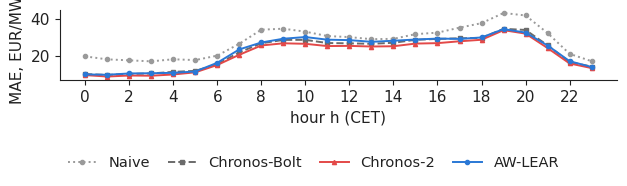

In [7]:
def mae(F):
    return np.mean(np.abs(A - F))


def nw_var(x, lags=7):
    x = x - x.mean()
    n = len(x)
    v = x @ x / n
    for k in range(1, lags + 1):
        v += 2 * (1 - k / (lags + 1)) * (x[k:] @ x[:-k]) / n
    return v


def dm(ea, eb, lags=7):
    """One-sided DM test (as in L2): H1 = model b more accurate than model a; loss = daily mean |error| over 24 hours."""
    dlt = np.mean(np.abs(ea), 1) - np.mean(np.abs(eb), 1)
    stat = dlt.mean() / np.sqrt(nw_var(dlt, lags) / len(dlt))
    return stat, 1 - stats.norm.cdf(stat)


E = {k: A - FC[k] for k in ["naive", "bolt", "chr2", "aw_lear"]}
BYHOUR = {k: np.mean(np.abs(e), 0) for k, e in E.items()}
cov80 = ((A >= FC["chr2_q10"]) & (A <= FC["chr2_q90"])).mean() * 100      # coverage of the 10%-90% band
h24 = np.arange(24)
fig, ax = plt.subplots(figsize=(6.4, 1.9))
for k, ls, mk in [("naive", ":", "o"), ("bolt", "--", "s"), ("chr2", "-", "^"), ("aw_lear", "-", "o")]:
    ax.plot(h24, BYHOUR[k], color=COL[k], ls=ls, marker=mk, ms=3, label=LAB[k])
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour h (CET)")
ax.set_ylabel("MAE, EUR/MWh")
legend_bottom(fig, ncol=4)
save_chart(fig, "foundation_hour", bottom=0.22)

## Numbers on the slide

In [8]:
show('MAE Chronos-2, EUR/MWh', mae(FC['chr2']), '.2f')
show('MAE Chronos-Bolt', mae(FC['bolt']), '.2f')
show('MAE AW-LEAR', mae(FC['aw_lear']), '.2f')
show('Hours in which Chronos-2 beats AW-LEAR', int((BYHOUR['chr2'] < BYHOUR['aw_lear']).sum()), 'd')
show('DM p-value, AW-LEAR vs Chronos-2', dm(E['aw_lear'], E['chr2'])[1], '.4f')
show('DM p-value, AW-LEAR vs Chronos-Bolt', dm(E['aw_lear'], E['bolt'])[1], '.4f')
show('Coverage of the 10%-90% band of Chronos-2, %', cov80, '.1f')

MAE Chronos-2, EUR/MWh: 20.82
MAE Chronos-Bolt: 22.15
MAE AW-LEAR: 22.53
Hours in which Chronos-2 beats AW-LEAR: 24
DM p-value, AW-LEAR vs Chronos-2: 0.0006
DM p-value, AW-LEAR vs Chronos-Bolt: 0.2201
Coverage of the 10%-90% band of Chronos-2, %: 76.5
